# Experiment 7 — Abstract field weighting (2 × 2 × 4)

Compare stemming (off/on), stopword removal (off/on), and abstract boosts (1, 2, 4, 8) using Discounted CombSUM and 100 retrieved documents. **Boosts are applied at query time**, not as changes to BM25F's length-normalization parameters.

Run this notebook from `testing/` after generating `bm25_abstract_grid_results/`.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("bm25_abstract_grid_results")
if not ROOT.exists():
    ROOT = Path("testing/bm25_abstract_grid_results")
summary = pd.read_csv(ROOT / "summary.csv")
metrics = pd.read_csv(ROOT / "metrics.csv")
rankings = pd.read_csv(ROOT / "rankings.csv")
PLOTS = ROOT / "plots"
PLOTS.mkdir(exist_ok=True)
display(summary.head())
print("Rows:", len(metrics), "Configurations:", metrics.configuration.nunique())

,configuration,preprocessing,stemming,stopwords,abstract_weight,query_type,queries,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
0,stem0_stop0_abs1,stem0_stop0,0,0,1,academic,226,0.526917,0.346948,0.376198
1,stem0_stop0_abs1,stem0_stop0,0,0,1,overall,452,0.443768,0.279016,0.306037
2,stem0_stop0_abs1,stem0_stop0,0,0,1,student_style,226,0.360619,0.211083,0.235876
3,stem0_stop0_abs2,stem0_stop0,0,0,2,academic,226,0.552286,0.349889,0.383690
4,stem0_stop0_abs2,stem0_stop0,0,0,2,overall,452,0.457928,0.288800,0.315000


Rows: 7232 Configurations: 16


## 1. Overall performance

,configuration,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
37,stem1_stop1_abs1,0.4683,0.3069,0.3332
40,stem1_stop1_abs2,0.4733,0.3031,0.3320
43,stem1_stop1_abs4,0.4721,0.2990,0.3294
46,stem1_stop1_abs8,0.4706,0.2932,0.3247
28,stem1_stop0_abs2,0.4672,0.2877,0.3196
16,stem0_stop1_abs2,0.4498,0.2883,0.3152
4,stem0_stop0_abs2,0.4579,0.2888,0.3150
34,stem1_stop0_abs8,0.4547,0.2845,0.3139
10,stem0_stop0_abs8,0.4576,0.2799,0.3107
19,stem0_stop1_abs4,0.4435,0.2842,0.3101


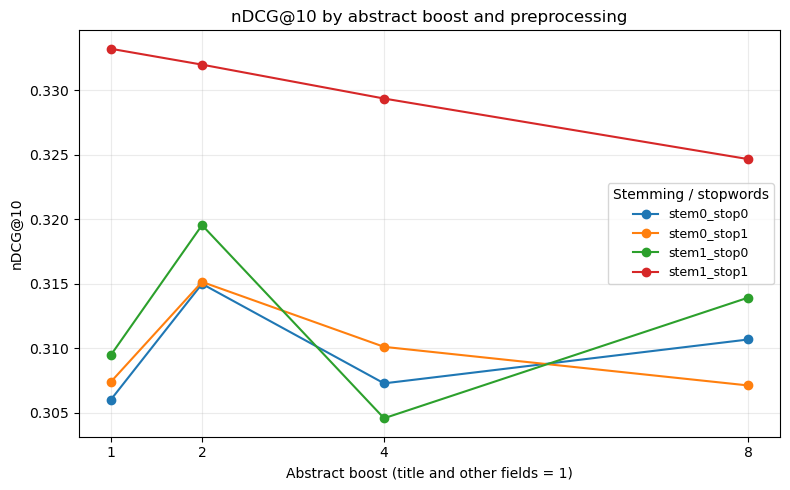

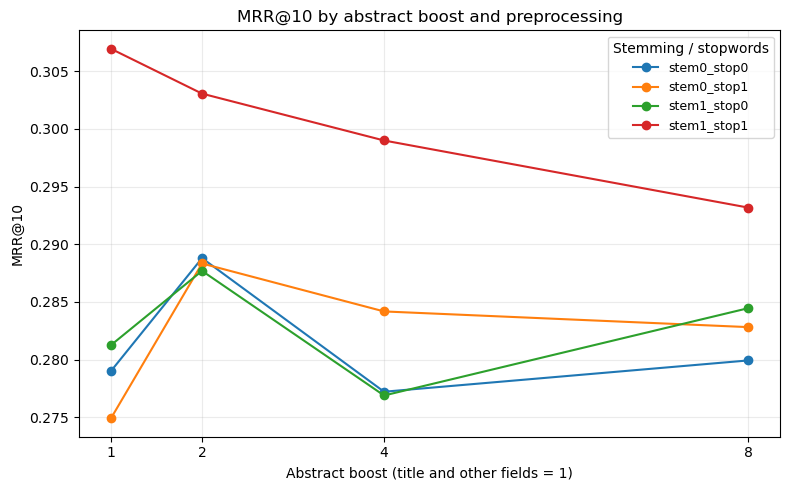

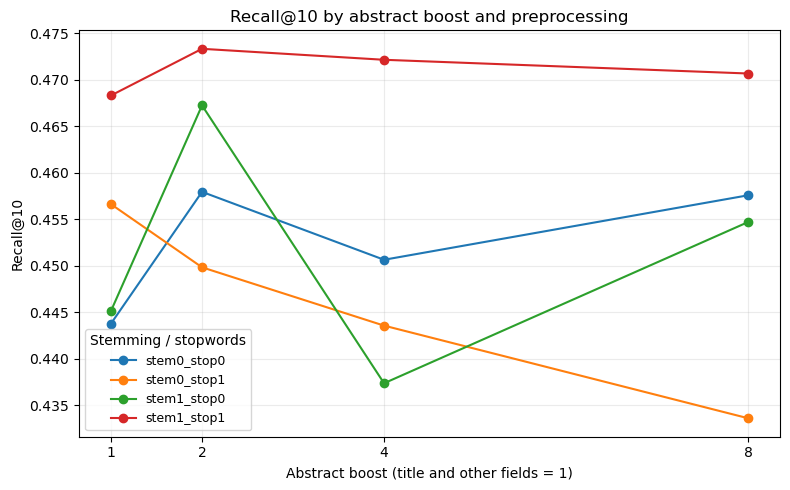

In [2]:
overall = summary.query("query_type == 'overall'").copy()
display(overall.sort_values('known_ndcg_at_k', ascending=False)[
    ['configuration','known_recall_at_k','known_mrr_at_k','known_ndcg_at_k']
].round(4))
for metric, title in [('known_ndcg_at_k','nDCG@10'),('known_mrr_at_k','MRR@10'),('known_recall_at_k','Recall@10')]:
    fig, ax = plt.subplots(figsize=(8,5))
    for name, group in overall.groupby('preprocessing'):
        group = group.sort_values('abstract_weight')
        ax.plot(group.abstract_weight, group[metric], marker='o', label=name)
    ax.set(xlabel='Abstract boost (title and other fields = 1)', ylabel=title,
           title=f'{title} by abstract boost and preprocessing')
    ax.set_xticks([1,2,4,8])
    ax.legend(title='Stemming / stopwords', fontsize=9)
    ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(PLOTS / f'overall_{metric}.png', dpi=180)
    plt.show()

## 2. Academic vs student-style queries

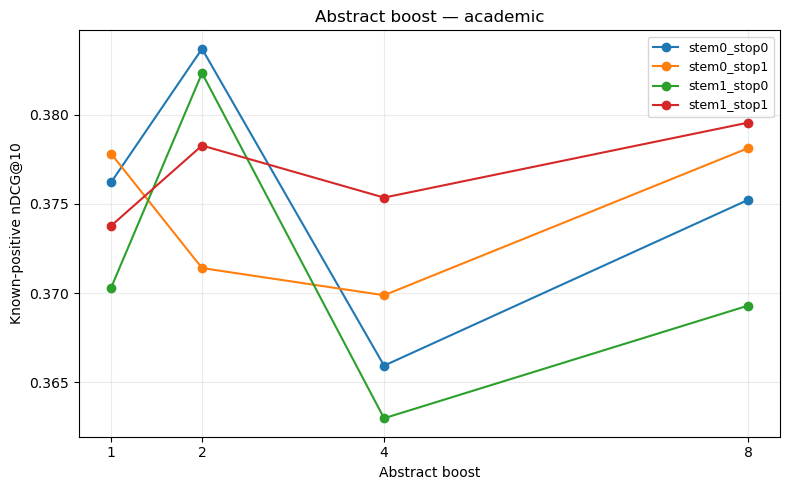

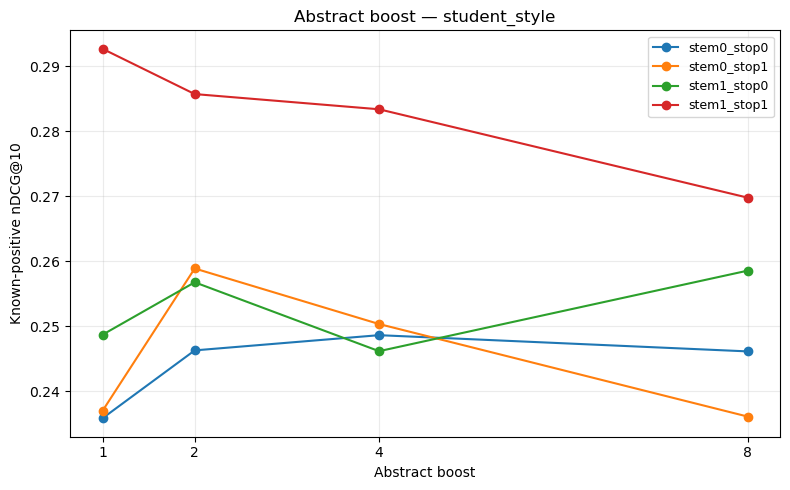

In [3]:
groups = summary.query("query_type != 'overall'")
for query_type, frame in groups.groupby('query_type'):
    fig, ax = plt.subplots(figsize=(8,5))
    for name, sub in frame.groupby('preprocessing'):
        sub = sub.sort_values('abstract_weight')
        ax.plot(sub.abstract_weight, sub.known_ndcg_at_k, marker='o', label=name)
    ax.set(xlabel='Abstract boost', ylabel='Known-positive nDCG@10',
           title=f'Abstract boost — {query_type}')
    ax.set_xticks([1,2,4,8])
    ax.legend(fontsize=9)
    ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(PLOTS / f'ndcg_{query_type}.png', dpi=180)
    plt.show()

## 3. Effect of abstract boosting relative to weight 1

abstract_weight,1,2,4,8
preprocessing,,,,
stem0_stop0,0.0,0.0090,0.0013,0.0047
stem0_stop1,0.0,0.0077,0.0027,-0.0003
stem1_stop0,0.0,0.0101,-0.0049,0.0044
stem1_stop1,0.0,-0.0012,-0.0039,-0.0085


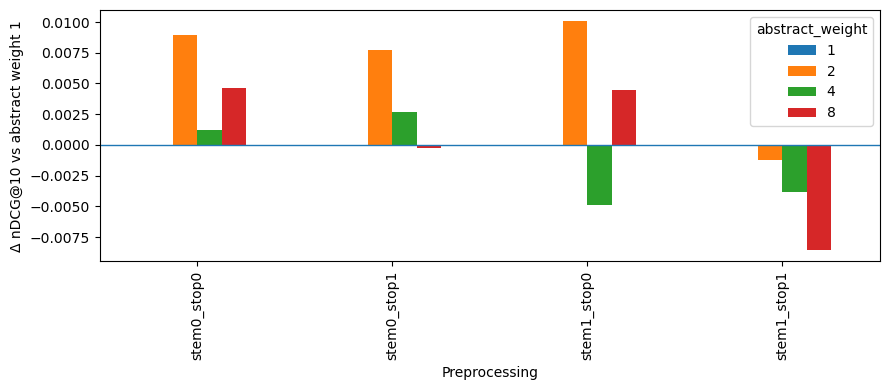

In [4]:
base = overall.loc[overall.abstract_weight == 1, ['preprocessing','known_ndcg_at_k']].rename(
    columns={'known_ndcg_at_k':'ndcg_weight1'})
deltas = overall.merge(base, on='preprocessing')
deltas['delta_ndcg'] = deltas.known_ndcg_at_k - deltas.ndcg_weight1
display(deltas.pivot(index='preprocessing', columns='abstract_weight', values='delta_ndcg').round(4))
fig, ax = plt.subplots(figsize=(9,4))
pivot = deltas.pivot(index='preprocessing', columns='abstract_weight', values='delta_ndcg')
pivot.plot(kind='bar', ax=ax)
ax.axhline(0, linewidth=1)
ax.set(ylabel='Δ nDCG@10 vs abstract weight 1', xlabel='Preprocessing')
fig.tight_layout()
fig.savefig(PLOTS/'delta_ndcg.png', dpi=180)
plt.show()

## 4. Ranking changes within each preprocessing configuration

In [5]:
rows=[]
for prep, frame in rankings.groupby(rankings.configuration.str.extract(r'^(stem[01]_stop[01])')[0]):
    baseline = frame[frame.configuration == f'{prep}_abs1']
    base_groups = {qid: g.sort_values('rank') for qid,g in baseline.groupby('query_id')}
    for weight in [2,4,8]:
        other = frame[frame.configuration == f'{prep}_abs{weight}']
        overlaps, top1 = [], []
        for qid,g in other.groupby('query_id'):
            if qid not in base_groups: continue
            a=base_groups[qid].researcher_uuid.tolist()
            b=g.sort_values('rank').researcher_uuid.tolist()
            overlaps.append(len(set(a)&set(b)))
            top1.append(int(bool(a and b) and a[0]==b[0]))
        rows.append(dict(preprocessing=prep, abstract_weight=weight,
                         mean_top10_overlap=np.mean(overlaps),
                         same_top1_rate=np.mean(top1)))
stability=pd.DataFrame(rows)
display(stability.round(3))

,preprocessing,abstract_weight,mean_top10_overlap,same_top1_rate
0,stem0_stop0,2,6.743,0.617
1,stem0_stop0,4,5.456,0.535
2,stem0_stop0,8,4.980,0.467
3,stem0_stop1,2,7.686,0.600
4,stem0_stop1,4,6.586,0.538
5,stem0_stop1,8,6.223,0.504
6,stem1_stop0,2,7.093,0.673
7,stem1_stop0,4,5.721,0.546
8,stem1_stop0,8,4.881,0.467
9,stem1_stop1,2,7.788,0.732


## 5. Paired bootstrap: best observed configuration vs. reference

Exploratory only: the best configuration is selected on these same queries, so this interval is **not** a confirmatory test. Queries originating from the same news article may be dependent.

In [6]:
metric='known_ndcg_at_k'
winner = overall.sort_values(metric, ascending=False).iloc[0]['configuration']
reference='stem1_stop1_abs1'
paired=metrics[metrics.configuration.isin([winner, reference])].pivot(
    index='query_id',columns='configuration',values=metric).dropna()
if winner == reference:
    print('Reference is already the top observed configuration.')
else:
    diff=(paired[winner]-paired[reference]).to_numpy()
    rng=np.random.default_rng(42)
    n_boot=10000
    boots=np.empty(n_boot)
    for i in range(n_boot):
        boots[i]=rng.choice(diff, size=len(diff), replace=True).mean()
    print('Winner:', winner, 'Reference:', reference)
    print('Mean paired difference:', round(diff.mean(),5))
    print('95% percentile CI:', np.quantile(boots,[.025,.975]).round(5))
    print('Queries improved / worsened / unchanged:',
          (diff>0).sum(), (diff<0).sum(), (diff==0).sum())
    fig,ax=plt.subplots(figsize=(7,4))
    ax.hist(boots,bins=45)
    ax.axvline(0,linestyle='--')
    ax.set(xlabel='Mean paired nDCG@10 difference',ylabel='Bootstrap frequency',
           title=f'{winner} vs {reference}')
    fig.tight_layout()
    fig.savefig(PLOTS/'exploratory_bootstrap.png',dpi=180)
    plt.show()

Reference is already the top observed configuration.


### Conclusion — Abstract Field Weighting

The experiment evaluated 16 combinations of stemming, stopword removal, and abstract field weights (1, 2, 4, and 8).

The highest observed nDCG@10 was achieved using stemming and stopword removal with an abstract weight of 1 (nDCG@10 = 0.3332).

Increasing abstract weight substantially changed the retrieved researcher rankings but did not improve overall performance against the existing test collection. For example, increasing the abstract weight from 1 to 8 reduced nDCG@10 to 0.3247.

An important limitation is that the relevance judgments are based on known-positive researchers identified from ITU news articles rather than exhaustive expert relevance assessments. Consequently, researchers not included in the expected-experts list may still be relevant. The evaluation therefore measures the system's ability to retrieve known experts rather than all potentially relevant experts.

Based on the observed results, equal field weights are retained for subsequent experiments. This decision is supported by the current evaluation framework, although further evaluation with more comprehensive relevance judgments would be needed to establish whether higher abstract weights improve expert discovery.